#Implementasi Segmentasi Otsu dan Operasi Morfologi Secara Manual

**Nama  :** Renata Ayu Sekar Kumala

**NIM   :** 25/557585/PA/23428

**Kelas :** PCD REG


**Tujuan**

1. Mengimplementasikan segmentasi Otsu tanpa fungsi segmentasi siap pakai.
2. Mengimplementasikan erosi, dilasi, opening, dan closing secara manual.
3. Membandingkan segmentasi tanpa morfologi dengan segmentasi setelah morfologi.
4. Menilai perubahan bentuk, ukuran, dan keterhubungan objek.

**Dasar teori**

1. Segmentasi Otsu

Otsu membagi piksel menjadi dua kelas berdasarkan intensitas. Ambang dipilih dengan memaksimalkan variansi antarkelas:

$$\sigma_B^2(t)=w_0(t)w_1(t)[\mu_0(t)-\mu_1(t)]^2$$

Bobot $w_0,w_1$ adalah proporsi piksel setiap kelas dan $\mu_0,\mu_1$ adalah reratanya. Menggunakan jumlah piksel sebagai bobot memberi ambang yang sama karena faktor skala tidak berubah terhadap ambang.

2. Operasi morfologi
Citra biner menyatakan foreground sebagai 1 dan background sebagai 0. Dengan citra $A$ dan structuring element $B$:

| Operasi | Notasi | Prinsip |
|---|---|---|
| Erosi | $A\ominus B$ | Semua posisi aktif kernel harus berada pada foreground |
| Dilasi | $A\oplus B$ | Mengembangkan foreground mengikuti bentuk kernel |
| Opening | $(A\ominus B)\oplus B$ | Erosi, kemudian dilasi |
| Closing | $(A\oplus B)\ominus B$ | Dilasi, kemudian erosi |

Opening dapat menghapus foreground kecil atau sambungan tipis. Closing dapat mengisi lubang kecil atau menyambungkan celah sempit. Efeknya bergantung pada bentuk dan ukuran kernel, detail yang valid juga dapat hilang.

**Ketentuan implementasi**

Algoritma grayscale, histogram, Otsu, morfologi, dan penghitungan komponen ditulis dengan Python dasar.

Kernel yang digunakan adalah persegi 3 × 3 dengan titik asal di tengah. Nilai di luar citra dianggap 0 (zero padding), sehingga objek pada tepi citra dapat terpengaruh.


**Persiapan**

Seluruh metode dibandingkan pada gambar yang sudah diperkecil dengan ukuran yang sama. Komponen di bawah batas luas hanya disebut komponen kecil, bukan otomatis noise.


In [1]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from collections import deque
from io import BytesIO

OBJEK_TERANG = True
UKURAN_MAKSIMUM = 384
BATAS_KOMPONEN_KECIL = 10

KERNEL = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
]


**Input Gambar**

Sumber gambar: [gambar koin dengan latar hitam bintik bintik](https://drive.google.com/file/d/1VSgH1l0pGGohAkq7gFdilhtd83KLOsFo/view?usp=sharing)

Saving koinkoin.png to koinkoin.png
File: koinkoin.png
Ukuran asli: (1254, 1254)
Ukuran eksperimen: (384, 384)


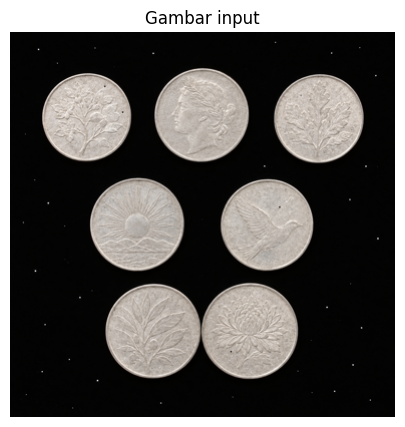

In [7]:
uploaded = files.upload()
if not uploaded:
    raise ValueError("Unggah satu gambar terlebih dahulu.")

filename = next(iter(uploaded))
image = Image.open(BytesIO(uploaded[filename])).convert("RGB")
original_size = image.size
image.thumbnail((UKURAN_MAKSIMUM, UKURAN_MAKSIMUM))

print("File:", filename)
print("Ukuran asli:", original_size)
print("Ukuran eksperimen:", image.size)

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Gambar input")
plt.axis("off")
plt.show()

**Implementasi Segmentasi**

**Grayscale manual**

Setiap piksel RGB diubah menjadi intensitas menggunakan:

$$Y=0.299R+0.587G+0.114B$$

**Otsu manual**

Langkah algoritma: hitung histogram, coba ambang 0–255, hitung variansi antarkelas, lalu pilih ambang terbaik. Jika beberapa ambang memiliki nilai maksimum sama, implementasi memilih yang pertama. Foreground ditentukan berdasarkan parameter OBJEK_TERANG.

Threshold Otsu: 93
Foreground: objek terang


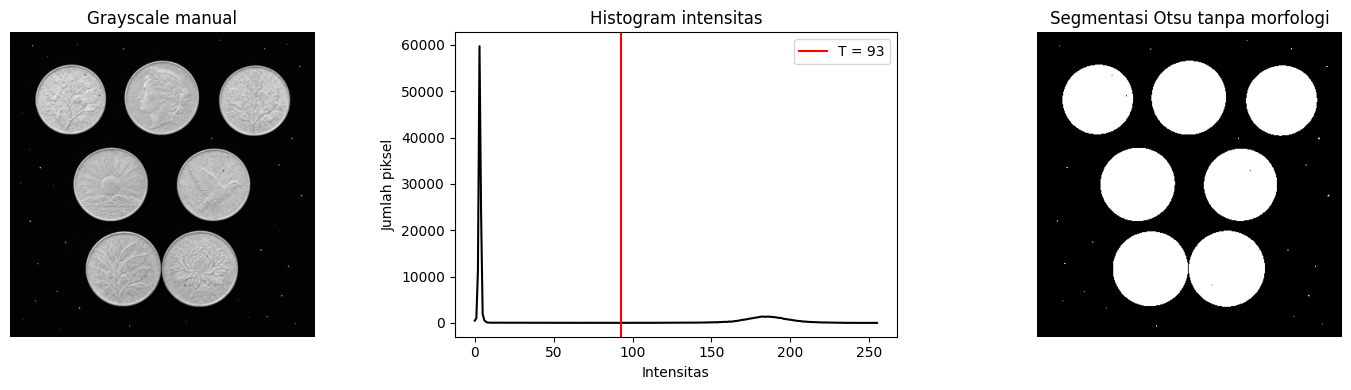

In [8]:
def grayscale_manual(image):
    width, height = image.size
    pixels = list(image.getdata())
    gray = []
    for y in range(height):
        row = []
        for x in range(width):
            r, g, b = pixels[y * width + x]
            row.append(round(0.299 * r + 0.587 * g + 0.114 * b))
        gray.append(row)
    return gray


def otsu_manual(gray, objek_terang=True):
    height, width = len(gray), len(gray[0])
    histogram = [0] * 256
    for row in gray:
        for value in row:
            histogram[value] += 1

    total = height * width
    total_sum = sum(i * histogram[i] for i in range(256))
    count_0, sum_0 = 0, 0
    best_variance, threshold = -1, 0

    for t in range(256):
        count_0 += histogram[t]
        sum_0 += t * histogram[t]
        if count_0 == 0:
            continue
        count_1 = total - count_0
        if count_1 == 0:
            break
        mean_0 = sum_0 / count_0
        mean_1 = (total_sum - sum_0) / count_1
        variance = count_0 * count_1 * (mean_0 - mean_1) ** 2
        if variance > best_variance:
            best_variance = variance
            threshold = t

    if best_variance < 0:
        raise ValueError("Intensitas gambar seragam. Gunakan gambar lain.")

    if objek_terang:
        binary = [[int(v > threshold) for v in row] for row in gray]
    else:
        binary = [[int(v <= threshold) for v in row] for row in gray]
    return threshold, binary, histogram


gray = grayscale_manual(image)
threshold, segmented, histogram = otsu_manual(gray, OBJEK_TERANG)

print("Threshold Otsu:", threshold)
print("Foreground:", "objek terang" if OBJEK_TERANG else "objek gelap")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale manual")
axes[0].axis("off")
axes[1].plot(range(256), histogram, color="black")
axes[1].axvline(threshold, color="red", label=f"T = {threshold}")
axes[1].set_title("Histogram intensitas")
axes[1].set_xlabel("Intensitas")
axes[1].set_ylabel("Jumlah piksel")
axes[1].legend()
axes[2].imshow(segmented, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Segmentasi Otsu tanpa morfologi")
axes[2].axis("off")
plt.tight_layout()
plt.show()


**Implementasi morfologi manual**

Untuk setiap piksel, program memeriksa posisi aktif kernel. Erosi mempertahankan nilai 1 jika seluruh posisi cocok, dilasi menghasilkan nilai 1 jika ada foreground yang menjangkau posisi tersebut.


In [9]:
def morphology_manual(binary, kernel, operation):
    height, width = len(binary), len(binary[0])
    kh, kw = len(kernel), len(kernel[0])
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Ukuran kernel harus ganjil.")
    if any(len(row) != kw for row in kernel):
        raise ValueError("Kernel harus berbentuk persegi panjang.")

    cy, cx = kh // 2, kw // 2
    offsets = [
        (ky - cy, kx - cx)
        for ky in range(kh)
        for kx in range(kw)
        if kernel[ky][kx] == 1
    ]
    if not offsets:
        raise ValueError("Kernel harus memiliki minimal satu elemen aktif.")
    if operation not in ("erosion", "dilation"):
        raise ValueError("Operasi tidak dikenal.")

    result = [[0] * width for _ in range(height)]
    for y in range(height):
        for x in range(width):
            if operation == "erosion":
                value = 1
                for dy, dx in offsets:
                    ny, nx = y + dy, x + dx
                    if not (0 <= ny < height and 0 <= nx < width):
                        value = 0
                        break
                    if binary[ny][nx] == 0:
                        value = 0
                        break
            else:
                value = 0
                for dy, dx in offsets:
                    # Refleksi kernel sesuai definisi dilasi.
                    ny, nx = y - dy, x - dx
                    if (0 <= ny < height and 0 <= nx < width
                            and binary[ny][nx] == 1):
                        value = 1
                        break
            result[y][x] = value
    return result


def erosion(binary, kernel):
    return morphology_manual(binary, kernel, "erosion")


def dilation(binary, kernel):
    return morphology_manual(binary, kernel, "dilation")


def opening(binary, kernel):
    return dilation(erosion(binary, kernel), kernel)


def closing(binary, kernel):
    return erosion(dilation(binary, kernel), kernel)


**Rancangan eksperimen**

Setiap operasi tunggal diterapkan langsung pada segmentasi awal, sehingga efeknya dapat dibandingkan secara terpisah. Eksperimen gabungan menerapkan opening lalu closing.

| Kondisi | Urutan pemrosesan |
|---|---|
| Baseline | Otsu |
| Erosi | Otsu → erosi |
| Dilasi | Otsu → dilasi |
| Opening | Otsu → erosi → dilasi |
| Closing | Otsu → dilasi → erosi |
| Gabungan | Otsu → opening → closing |

Semua kondisi menggunakan ambang Otsu, polaritas foreground, ukuran gambar, dan kernel yang sama. Gabungan dipilih untuk memeriksa efek penghapusan foreground kecil diikuti pengisian celah kecil, hasilnya tidak diasumsikan selalu paling baik.

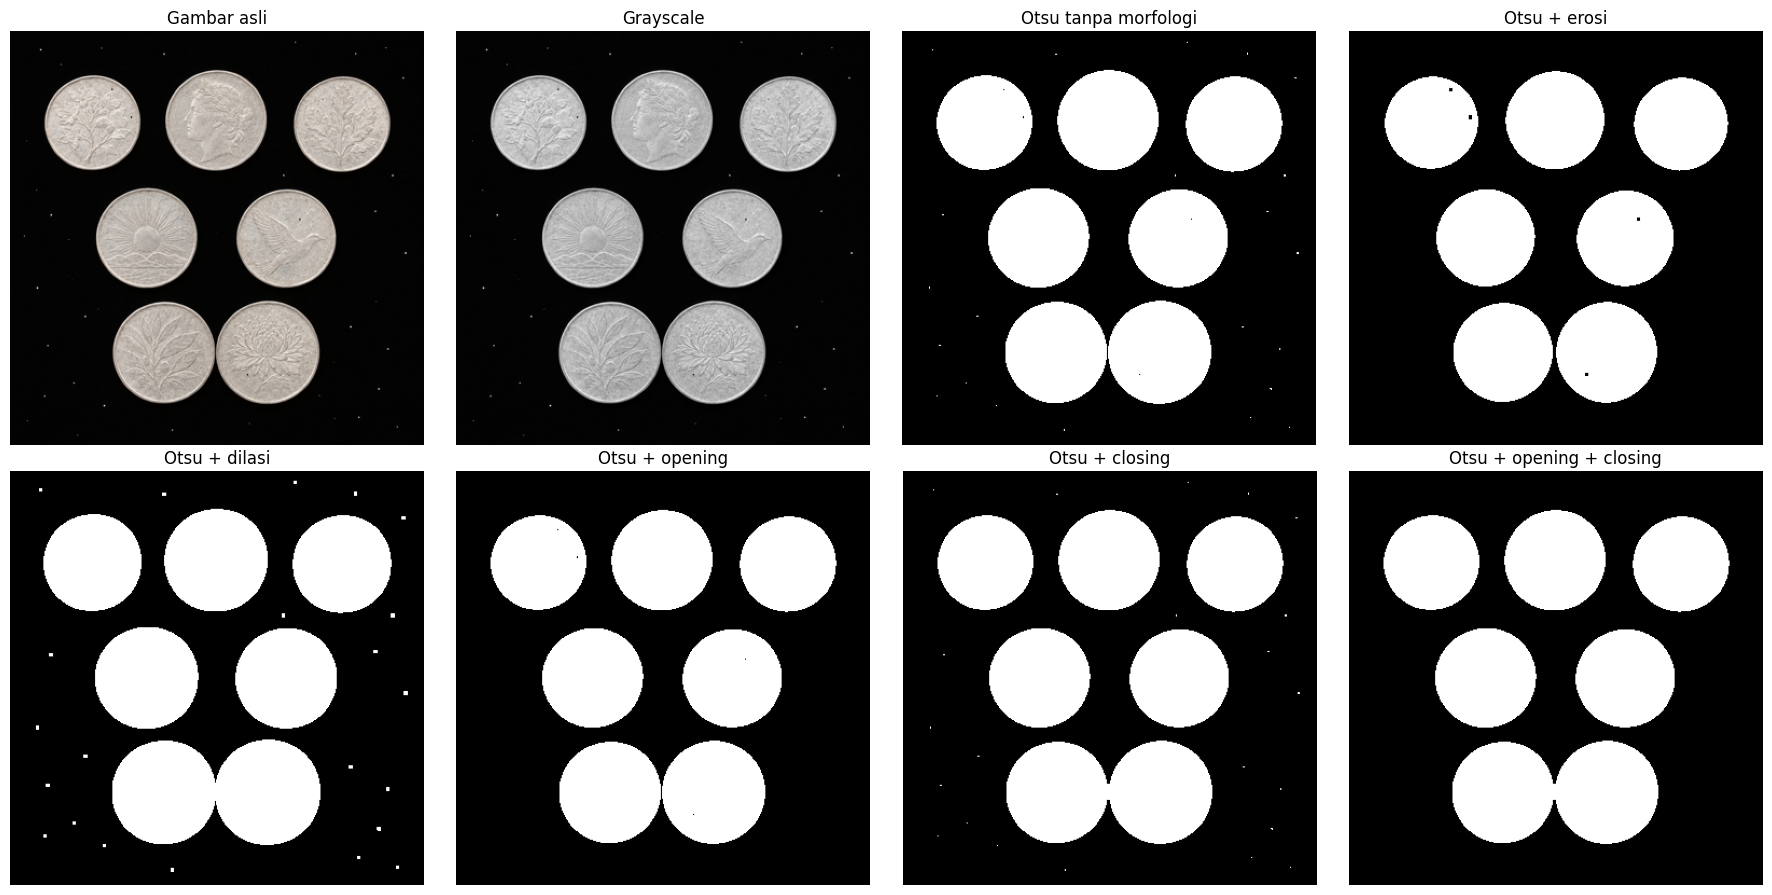

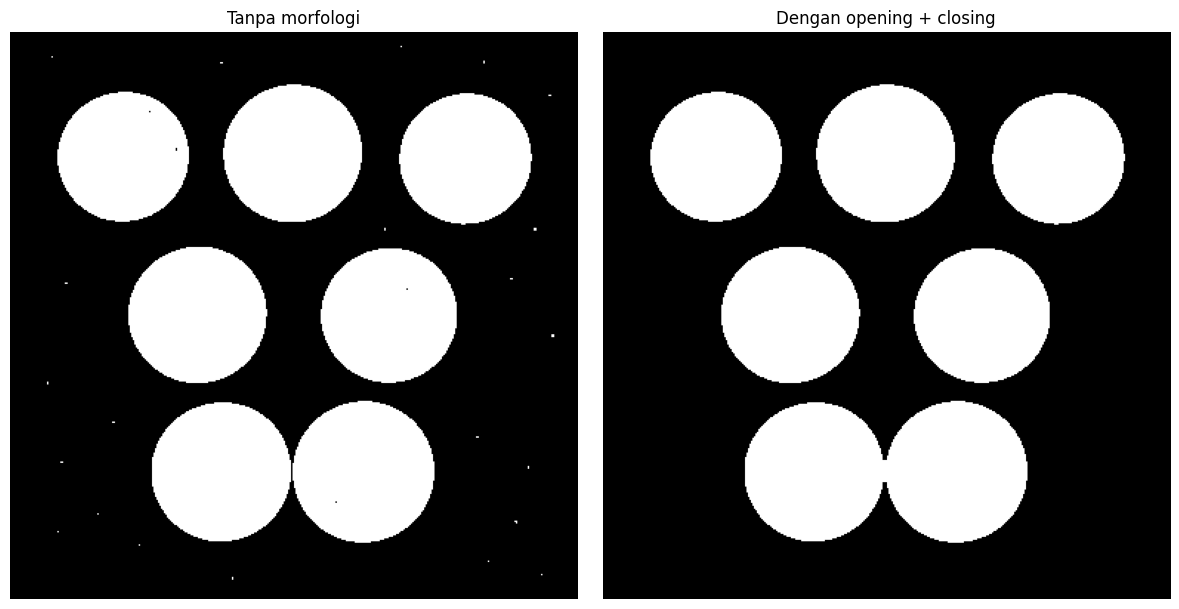

In [10]:
eroded = erosion(segmented, KERNEL)
dilated = dilation(segmented, KERNEL)
opened = opening(segmented, KERNEL)
closed = closing(segmented, KERNEL)
final_result = closing(opened, KERNEL)

results = {
    "Otsu tanpa morfologi": segmented,
    "Otsu + erosi": eroded,
    "Otsu + dilasi": dilated,
    "Otsu + opening": opened,
    "Otsu + closing": closed,
    "Otsu + opening + closing": final_result
}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
panels = [("Gambar asli", image), ("Grayscale", gray)] + list(results.items())
for ax, (title, data) in zip(axes.flat, panels):
    if title == "Gambar asli":
        ax.imshow(data)
    else:
        ax.imshow(data, cmap="gray", vmin=0,
                  vmax=255 if title == "Grayscale" else 1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, title, data in [
    (axes[0], "Tanpa morfologi", segmented),
    (axes[1], "Dengan opening + closing", final_result)
]:
    ax.imshow(data, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Perbandingan kuantitatif**

Pengukuran ditulis manual dan dilakukan untuk semua kondisi:
- jumlah serta persentase piksel foreground
- jumlah komponen foreground dengan konektivitas 8
- jumlah komponen dengan luas kurang dari 10 piksel
- persentase piksel yang berubah dibandingkan baseline.

**Batas interpretasi:** komponen bukan selalu objek nyata. Satu objek dapat terpecah menjadi beberapa komponen, atau beberapa objek dapat bergabung menjadi satu. Tanpa anotasi acuan (ground truth), metrik ini bukan akurasi segmentasi.


In [11]:
def component_sizes(binary):
    height, width = len(binary), len(binary[0])
    visited = [[False] * width for _ in range(height)]
    neighbors = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1), (0, 1),
        (1, -1), (1, 0), (1, 1)
    ]
    sizes = []
    for y in range(height):
        for x in range(width):
            if not binary[y][x] or visited[y][x]:
                continue
            queue = deque([(y, x)])
            visited[y][x] = True
            size = 0
            while queue:
                py, px = queue.popleft()
                size += 1
                for dy, dx in neighbors:
                    ny, nx = py + dy, px + dx
                    if (0 <= ny < height and 0 <= nx < width
                            and binary[ny][nx] and not visited[ny][nx]):
                        visited[ny][nx] = True
                        queue.append((ny, nx))
            sizes.append(size)
    return sizes


height, width = len(segmented), len(segmented[0])
total_pixels = height * width
measurements = {}
for name, binary in results.items():
    sizes = component_sizes(binary)
    area = sum(sum(row) for row in binary)
    changed = sum(
        binary[y][x] != segmented[y][x]
        for y in range(height)
        for x in range(width)
    )
    measurements[name] = {
        "area": area,
        "area_percent": 100 * area / total_pixels,
        "components": len(sizes),
        "small": sum(s < BATAS_KOMPONEN_KECIL for s in sizes),
        "changed_percent": 100 * changed / total_pixels
    }

table = (
    "| Kondisi | Piksel foreground | Foreground (%) | Komponen (8) | "
    f"Komponen <{BATAS_KOMPONEN_KECIL} piksel | Piksel berubah (%) |\n"
    "|---|---:|---:|---:|---:|---:|\n"
)
for name, m in measurements.items():
    table += (
        f"| {name} | {m['area']} | {m['area_percent']:.2f} | "
        f"{m['components']} | {m['small']} | "
        f"{m['changed_percent']:.2f} |\n"
    )
display(Markdown(table))

before = measurements["Otsu tanpa morfologi"]
after = measurements["Otsu + opening + closing"]
display(Markdown(
    f"**Ringkasan hasil terukur:** threshold Otsu = **{threshold}**. "
    f"Pada gabungan opening dan closing, luas foreground berubah dari "
    f"**{before['area']}** menjadi **{after['area']}** piksel; "
    f"jumlah komponen berubah dari **{before['components']}** menjadi "
    f"**{after['components']}**; komponen kecil berubah dari "
    f"**{before['small']}** menjadi **{after['small']}**. "
    f"Sebanyak **{after['changed_percent']:.2f}%** piksel berubah "
    f"terhadap baseline. Perubahan ini perlu dinilai bersama visualisasi."
))


| Kondisi | Piksel foreground | Foreground (%) | Komponen (8) | Komponen <10 piksel | Piksel berubah (%) |
|---|---:|---:|---:|---:|---:|
| Otsu tanpa morfologi | 46838 | 31.76 | 29 | 22 | 0.00 |
| Otsu + erosi | 44206 | 29.98 | 7 | 0 | 1.78 |
| Otsu + dilasi | 49653 | 33.67 | 28 | 7 | 1.91 |
| Otsu + opening | 46796 | 31.74 | 7 | 0 | 0.03 |
| Otsu + closing | 46861 | 31.78 | 28 | 22 | 0.02 |
| Otsu + opening + closing | 46819 | 31.75 | 6 | 0 | 0.04 |


**Ringkasan hasil terukur:** threshold Otsu = **93**. Pada gabungan opening dan closing, luas foreground berubah dari **46838** menjadi **46819** piksel; jumlah komponen berubah dari **29** menjadi **6**; komponen kecil berubah dari **22** menjadi **0**. Sebanyak **0.04%** piksel berubah terhadap baseline. Perubahan ini perlu dinilai bersama visualisasi.

**Analisis Hasil**

**1. Hasil Segmentasi Otsu**

Pengujian menggunakan gambar sintetis tujuh koin terang pada latar hitam yang memuat titik putih kecil serta beberapa bintik gelap pada permukaan koin. Gambar berukuran awal 1254 × 1254 piksel diperkecil menjadi 384 × 384 piksel untuk mempercepat pemrosesan.

Metode Otsu menghasilkan nilai ambang **93**. Dengan pengaturan OBJEK_TERANG = True, piksel dengan intensitas di atas ambang menjadi foreground putih, sedangkan piksel lainnya menjadi background hitam. Pengaturan ini sesuai karena koin memiliki intensitas lebih tinggi daripada latarnya.

Secara visual, segmentasi berhasil memisahkan siluet koin dari latar. Namun, titik putih kecil pada latar juga terdeteksi sebagai foreground. Hasil awal memiliki **46838 piksel foreground**, yaitu **31,76%** dari seluruh piksel, dengan **29 komponen terhubung**. Sebanyak **22 komponen** memiliki luas kurang dari 10 piksel. Pada gambar ini, komponen kecil tersebut sesuai dengan titik putih pengganggu, sedangkan tujuh komponen lainnya merepresentasikan koin.

**2. Pengaruh Erosi dan Dilasi**

**Erosi** mengurangi jumlah piksel foreground dari **46838 menjadi 44206**, dengan perubahan sebesar **1,78%** terhadap baseline. Titik putih kecil menghilang sehingga jumlah komponen turun menjadi **7**, tanpa komponen berukuran kurang dari 10 piksel.

Meskipun dapat menghilangkan titik kecil, erosi juga menyusutkan seluruh siluet koin dan memperbesar bintik background pada permukaan koin. Oleh karena itu, erosi saja kurang sesuai jika ukuran dan bentuk objek perlu dipertahankan.

**Dilasi** meningkatkan jumlah piksel foreground menjadi **49653**, dengan perubahan sebesar **1,91%**. Siluet koin membesar dan dua koin di bagian bawah menyatu. Titik putih pada latar juga membesar sehingga dilasi tidak sesuai untuk menghilangkan gangguan foreground kecil.

Setelah dilasi, jumlah komponen menjadi **28**, sedangkan komponen berukuran kurang dari 10 piksel menjadi **7**. Penurunan jumlah komponen kecil tidak berarti seluruh titik pengganggu terhapus. Sebagian titik membesar melewati batas 10 piksel sehingga tidak lagi masuk kategori komponen kecil.

**3. Pengaruh Opening dan Closing**

**Opening** menghasilkan **46796 piksel foreground**, **7 komponen terhubung**, dan **0 komponen kecil**. Perubahan terhadap baseline hanya sebesar **0,03%**.

Hasil visual menunjukkan titik putih pada latar menghilang, sementara tujuh koin tetap terpisah. Luas foreground hanya berkurang bersih sebanyak **42 piksel**, jauh lebih kecil daripada pengurangan akibat erosi. Hal ini menunjukkan bahwa opening dapat menghilangkan titik kecil sambil mempertahankan sebagian besar wilayah koin.

**Closing** menghasilkan **46861 piksel foreground**, **28 komponen terhubung**, dan **22 komponen kecil**, dengan perubahan sebesar **0,02%**. Bintik gelap kecil pada koin tertutup, tetapi titik putih pada latar tetap ada.

Closing juga menyambungkan dua koin di bagian bawah. Penurunan jumlah komponen dari 29 menjadi 28 berkaitan dengan penggabungan tersebut, bukan penghapusan titik putih pengganggu. Dengan demikian, closing membantu mengisi lubang kecil, tetapi dapat mengurangi keterpisahan objek.


**4. Perbandingan Tanpa Morfologi dan Dengan Opening–Closing**

Hasil perbandingan utama adalah sebagai berikut.

| Parameter | Tanpa morfologi | Opening kemudian closing |
|---|---:|---:|
| Jumlah piksel foreground | 46838 | 46819 |
| Persentase foreground | 31,76% | 31,75% |
| Jumlah komponen terhubung | 29 | 6 |
| Komponen berukuran <10 piksel | 22 | 0 |
| Piksel berubah terhadap baseline | 0,00% | 0,04% |

Gabungan opening dan closing menghilangkan titik putih kecil serta menutup bintik gelap kecil pada koin. Secara visual, citra menjadi lebih bersih dengan perubahan piksel hanya **0,04%** terhadap baseline.

Namun, jumlah komponen akhirnya menjadi **6**, padahal gambar memuat tujuh koin. Berdasarkan visualisasi, dua koin di bagian bawah menyatu setelah closing. Penurunan jumlah komponen dari 29 menjadi 6 mencerminkan penghilangan 22 komponen kecil sekaligus penggabungan dua komponen koin.

Jumlah piksel foreground berkurang bersih sebanyak **19 piksel**. Nilai ini merupakan selisih luas akhir dan awal, bukan jumlah seluruh piksel yang berubah, karena rangkaian operasi dapat menghapus sebagian piksel sekaligus menambahkan piksel lain.

**5. Evaluasi Metode**

Untuk tujuan membersihkan titik pengganggu sambil mempertahankan setiap koin sebagai objek terpisah, **opening memberikan hasil paling sesuai di antara kondisi yang diuji**. Operasi ini menghilangkan seluruh 22 komponen kecil, mempertahankan tujuh komponen koin, dan hanya mengubah 0,03% piksel.

Gabungan opening dan closing menghasilkan citra yang lebih bersih dari titik putih serta bintik gelap, tetapi menggabungkan dua koin yang berdekatan. Oleh karena itu, hasil gabungan kurang sesuai apabila tahap berikutnya adalah menghitung koin berdasarkan komponen terhubung.

Pengujian ini menunjukkan bahwa citra yang tampak lebih bersih belum tentu lebih sesuai untuk setiap tujuan. Penilaian perlu mempertimbangkan penghilangan gangguan sekaligus pemeliharaan bentuk dan keterpisahan objek.

**6. Keterbatasan**

Hasil eksperimen bergantung pada ukuran gambar, nilai ambang, serta bentuk dan ukuran kernel. Pengecilan gambar dapat mengubah detail kecil dan jarak antarkoin. Kernel 3 × 3 juga dapat menghilangkan detail yang valid atau menyambungkan objek yang berdekatan.

Pengujian menggunakan gambar sintetis dengan kontras tinggi sehingga belum mewakili seluruh kondisi gambar nyata. Selain itu, tidak tersedia ground truth berupa mask acuan. Oleh karena itu, hasil pengukuran menunjukkan perubahan struktur citra dan belum dapat digunakan untuk menyatakan peningkatan akurasi segmentasi secara kuantitatif.

**Kesimpulan**

1. Metode segmentasi Otsu dan operasi erosi, dilasi, opening, serta closing berhasil diimplementasikan secara manual. Pada gambar berukuran 384 × 384 piksel, Otsu menghasilkan nilai ambang 93.

2. Segmentasi awal berhasil memisahkan siluet koin dari latar, tetapi masih mendeteksi titik putih pengganggu. Hasilnya terdiri atas 29 komponen terhubung, yaitu tujuh komponen koin dan 22 komponen kecil.

3. Opening merupakan operasi paling sesuai untuk membersihkan titik kecil sekaligus mempertahankan keterpisahan koin pada pengujian ini. Hasilnya memiliki tujuh komponen, tanpa komponen kecil, dengan perubahan piksel sebesar 0,03%.

4. Gabungan opening dan closing menghilangkan komponen kecil serta menutup bintik gelap, tetapi menggabungkan dua koin bawah sehingga hanya tersisa 6 komponen terhubung. Hasil ini kurang sesuai untuk penghitungan tujuh koin menggunakan komponen terhubung.

5. Pemrosesan morfologi perlu dipilih berdasarkan tujuan segmentasi. Penghilangan gangguan harus diseimbangkan dengan pemeliharaan bentuk dan keterpisahan objek.